In [129]:
import numpy as np
import tensorflow as tf
import pandas as pd
import tensorflow_probability as tfp

from skimage.morphology import skeletonize, thin

In [130]:
root = """data\\"""
img_size = (128, 128)

In [131]:
src = pd.read_csv("data\english.csv")
# src.head()

In [132]:
def load_img(name):
    loc = root + name.rstrip()
    img = tf.keras.preprocessing.image.load_img(loc, target_size=img_size, color_mode="grayscale")
    img = tf.convert_to_tensor(img, dtype=tf.float32) / 255.0
    img = 1 - img
    return img

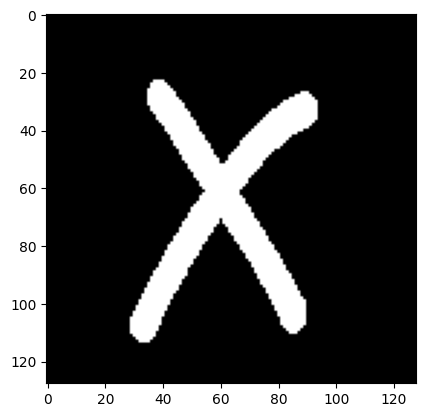

In [147]:
import matplotlib.pyplot as plt

i = load_img("Img/img034-001.png	")
plt.imshow(i, cmap='gray', vmin=0, vmax=1)

Make the image blurry

In [179]:
def randomise(image: tf.Tensor):
    random_values = tf.random.uniform(shape=(8,8,1), minval=0.1, maxval=1.0)
    random_values = tf.reshape(tf.image.resize(random_values, img_size, method="bilinear"), img_size)
    mask = tf.equal(image, 1.0)
    return tf.where(mask, random_values, image)

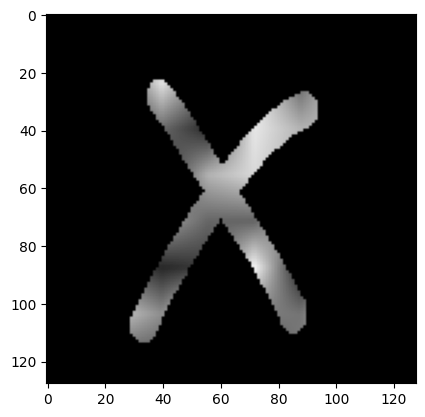

In [180]:
blur = randomise(i)
plt.imshow(blur, cmap='gray', vmin=0, vmax=1)

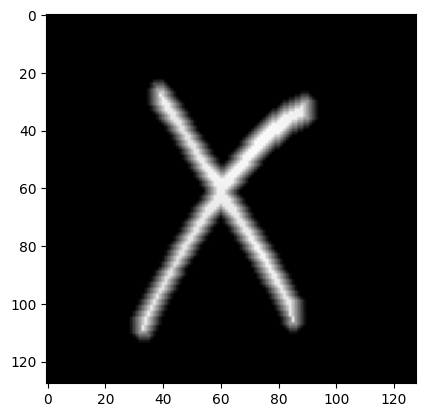

In [182]:
sk = thin(blur.numpy(), 1)

skeletons = [blur, tf.constant(sk, dtype=tf.float32)]

for j in range(4):
    sk = thin(sk, 1)
    skeletons.append(tf.constant(sk, dtype=tf.float32))

# Average it out; enh = enhanced
enh = tf.add_n(skeletons) / len(skeletons)
plt.imshow(enh, cmap='gray', vmin=0, vmax=1)

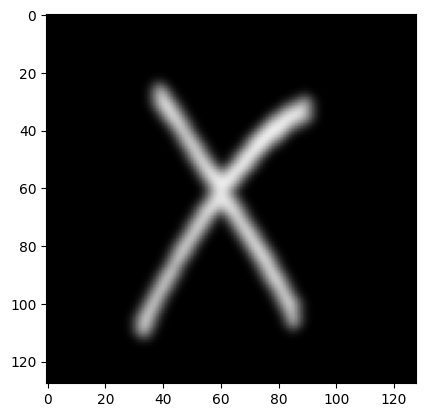

In [183]:
def gaussian_kernel(size: int, mean: float, std: float):
    """Generates a Gaussian kernel to be used for blurring"""
    d = tfp.distributions.Normal(mean, std)
    vals = d.prob(tf.range(start=-size, limit=size+1, dtype=tf.float32))
    gauss_kernel = tf.einsum('i,j->ij', vals, vals)
    gauss_kernel = gauss_kernel / tf.reduce_sum(gauss_kernel)  # Normalize the kernel
    return gauss_kernel[:, :, tf.newaxis, tf.newaxis]

def apply_gaussian_blur(image: tf.Tensor, kernel_size: int, sigma: float):
    kernel = gaussian_kernel(kernel_size, 0., sigma)
    kernel = tf.tile(kernel, [1, 1, image.shape[-1], 1])  # Adjust the kernel to work for each image channel
    image = tf.expand_dims(image, axis=0)  # Add a batch dimension for convolution
    blurred_image = tf.nn.depthwise_conv2d(image, kernel, strides=[1, 1, 1, 1], padding='SAME')
    return tf.squeeze(blurred_image, axis=0)  # Remove the batch dimension

blur = tf.reshape(enh, [128, 128, 1])
blur = apply_gaussian_blur(blur, 20, 1.5)
plt.imshow(blur, cmap='gray', vmin=0, vmax=1)

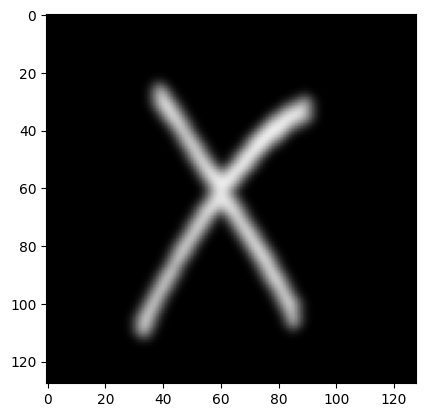

In [184]:
final = randomise(tf.reshape(blur, img_size))
plt.imshow(final, cmap='gray', vmin=0, vmax=1)

------------